In [1]:
import tensorflow as tf

model = tf.keras.models.load_model(
    "E:/Radiomics/attention_model.keras",
    compile=False
)

print("Model loaded successfully")


Model loaded successfully


In [2]:
print("Input shape :", model.input_shape)
print("Output shape:", model.output_shape)


Input shape : (None, 112, 112, 112, 4)
Output shape: (None, 112, 112, 112, 4)


In [ ]:
last_layer = model.layers[-1]
print("Last layer type:", type(last_layer))
print("Activation:", last_layer.activation)


Last layer type: <class 'keras.src.layers.convolutional.conv3d.Conv3D'>
Activation: <function softmax at 0x000001746388F520>


In [4]:
import numpy as np

dummy_input = np.random.rand(1, 112, 112, 112, 4).astype(np.float32)

pred = model.predict(dummy_input)

print("Prediction shape:", pred.shape)
print("Min value:", pred.min())
print("Max value:", pred.max())


1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step
Prediction shape: (1, 112, 112, 112, 4)
Min value: 0.00011279449
Max value: 0.9993431


In [5]:
segmentation_labels = np.argmax(pred, axis=-1)

print("Segmentation shape:", segmentation_labels.shape)
print("Unique labels:", np.unique(segmentation_labels))


Segmentation shape: (1, 112, 112, 112)
Unique labels: [0 1 2 3]


In [7]:
import numpy as np
import nibabel as nib
from scipy.ndimage import zoom

# Load all 4 modalities
data_path = r"E:\Radiomics\example"
modalities = ['t1', 't1ce', 't2', 'flair']

images = []
for modality in modalities:
    file_path = f"{data_path}\\BraTS2021_00000_{modality}.nii.gz"
    nifti_img = nib.load(file_path)
    image_data = nifti_img.get_fdata()
    images.append(image_data)
    print(f"{modality} shape: {image_data.shape}")

# Stack the 4 modalities along the last axis
image_volume = np.stack(images, axis=-1)
print(f"\nStacked volume shape: {image_volume.shape}")

# Check if we need to resize to 112x112x112
target_shape = (112, 112, 112)
current_shape = image_volume.shape[:3]

if current_shape != target_shape:
    print(f"Resizing from {current_shape} to {target_shape}...")
    zoom_factors = [target_shape[i] / current_shape[i] for i in range(3)] + [1]
    image_volume = zoom(image_volume, zoom_factors, order=1)
    print(f"Resized volume shape: {image_volume.shape}")

# Add batch dimension
input_tensor = np.expand_dims(image_volume, axis=0).astype(np.float32)
print(f"Input tensor shape: {input_tensor.shape}")

# Predict
pred = model.predict(input_tensor)

# Remove batch dimension
pred = pred[0]

# Get class per voxel
seg = np.argmax(pred, axis=-1)

print(f"\nSegmentation shape: {seg.shape}")
print(f"Unique labels: {np.unique(seg)}")

t1 shape: (240, 240, 155)
t1ce shape: (240, 240, 155)
t2 shape: (240, 240, 155)
flair shape: (240, 240, 155)

Stacked volume shape: (240, 240, 155, 4)
Resizing from (240, 240, 155) to (112, 112, 112)...
Resized volume shape: (112, 112, 112, 4)
Input tensor shape: (1, 112, 112, 112, 4)
1/1 ━━━━━━━━━━━━━━━━━━━━ 10s 10s/step

Segmentation shape: (112, 112, 112)
Unique labels: [0 1 2 3]


Segments convertion

In [14]:
import os
import numpy as np
import nibabel as nib
import tensorflow as tf
from tqdm import tqdm


In [15]:
# Define custom loss and metric functions
import tensorflow.keras.backend as K

def dice_coef(y_true, y_pred, smooth=1.0):
    """Dice coefficient for binary or multi-class segmentation"""
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    return (2. * intersection + smooth) / (K.sum(y_true_f) + K.sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    """Dice loss"""
    return 1 - dice_coef(y_true, y_pred)

def combined_dice_ce_loss(y_true, y_pred):
    """Combined Dice and Cross-Entropy loss"""
    dice = dice_loss(y_true, y_pred)
    ce = tf.keras.losses.categorical_crossentropy(y_true, y_pred)
    return dice + ce

def dice_whole_tumor(y_true, y_pred):
    """Dice coefficient for whole tumor (all tumor classes combined)"""
    # Classes 1, 2, 3 are tumor regions
    y_true_wt = K.sum(y_true[..., 1:], axis=-1)
    y_pred_wt = K.sum(y_pred[..., 1:], axis=-1)
    return dice_coef(y_true_wt, y_pred_wt)

def dice_tumor_core(y_true, y_pred):
    """Dice coefficient for tumor core (classes 1 and 3)"""
    # Tumor core includes enhancing tumor and necrotic core
    y_true_tc = y_true[..., 1] + y_true[..., 3]
    y_pred_tc = y_pred[..., 1] + y_pred[..., 3]
    return dice_coef(y_true_tc, y_pred_tc)

def dice_enhancing_tumor(y_true, y_pred):
    """Dice coefficient for enhancing tumor (class 3)"""
    y_true_et = y_true[..., 3]
    y_pred_et = y_pred[..., 3]
    return dice_coef(y_true_et, y_pred_et)

def iou_coef(y_true, y_pred, smooth=1.0):
    """Intersection over Union coefficient"""
    y_true_f = K.flatten(y_true)
    y_pred_f = K.flatten(y_pred)
    intersection = K.sum(y_true_f * y_pred_f)
    union = K.sum(y_true_f) + K.sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

print("Custom loss and metric functions defined")

Custom loss and metric functions defined


In [16]:
model = tf.keras.models.load_model(
    "E:/Radiomics/attention_model.keras",
    custom_objects={
        'combined_dice_ce_loss': combined_dice_ce_loss,
        'dice_whole_tumor': dice_whole_tumor,
        'dice_tumor_core': dice_tumor_core,
        'dice_enhancing_tumor': dice_enhancing_tumor,
        'iou_coef': iou_coef
    },
    compile=False
)


In [17]:
def load_nifti(path):
    nii = nib.load(path)
    return nii.get_fdata().astype(np.float32), nii.affine

In [18]:
def normalize_nonzero(vol):
    nz = vol[vol != 0]
    if nz.size > 0:
        vol = (vol - nz.mean()) / (nz.std() + 1e-8)
    return vol


In [19]:
def resize_volume(vol, target_shape=(112,112,112)):
    vol = tf.image.resize(vol, target_shape[:2]).numpy()
    vol = tf.transpose(vol, (2,0,1))
    vol = tf.image.resize(vol, (target_shape[2], target_shape[0])).numpy()
    return np.transpose(vol, (1,2,0))

In [20]:
DATA_DIR = "E:/Radiomics/example"
MASK_OUT_DIR = "E:/Radiomics/example_masks"

os.makedirs(MASK_OUT_DIR, exist_ok=True)

# Extract patient ID from example folder by finding first .nii.gz file
example_files = os.listdir(DATA_DIR)
patient_id = None
for f in example_files:
    if f.endswith('.nii.gz') and '_t1.nii.gz' in f:
        patient_id = f.replace('_t1.nii.gz', '')
        break

if patient_id is None:
    raise ValueError("No patient data found in example folder")

print(f"Processing patient: {patient_id}")

Processing patient: BraTS2021_00000


In [21]:
from scipy.ndimage import zoom

def resize_seg_back(seg, target_shape):
    zoom_factors = (
        target_shape[0] / seg.shape[0],
        target_shape[1] / seg.shape[1],
        target_shape[2] / seg.shape[2]
    )
    seg_resized = zoom(seg, zoom_factors, order=0)  # order=0 = nearest
    return seg_resized.astype(np.uint8)


In [22]:
pid = patient_id
pdir = DATA_DIR

vols = []
affine = None
orig_shape = None

for mod in ["t1", "t1ce", "t2", "flair"]:
    nii = nib.load(os.path.join(pdir, f"{pid}_{mod}.nii.gz"))
    vol = nii.get_fdata()

    if orig_shape is None:
        orig_shape = vol.shape
        affine = nii.affine

    vol = normalize_nonzero(vol)
    vol = resize_volume(vol)  # -> (112,112,112)
    vols.append(vol)

image_4ch = np.stack(vols, axis=-1)
input_tensor = np.expand_dims(image_4ch, axis=0)

# Predict
pred = model.predict(input_tensor, verbose=0)
seg_small = np.argmax(pred, axis=-1)[0].astype(np.uint8)

# RESAMPLE BACK
seg_full = resize_seg_back(seg_small, orig_shape)

# Save mask
out_path = os.path.join(MASK_OUT_DIR, f"{pid}_pred_seg.nii.gz")
nib.save(nib.Nifti1Image(seg_full, affine), out_path)

print(f"✅ Segmentation saved: {out_path}")

✅ Segmentation saved: E:/Radiomics/example_masks\BraTS2021_00000_pred_seg.nii.gz


In [23]:
import nibabel as nib

img = nib.load("E:/Radiomics/example/BraTS2021_00000_t1.nii.gz")
seg = nib.load("E:/Radiomics/example_masks/BraTS2021_00000_pred_seg.nii.gz")

print("Image shape:", img.shape)
print("Seg shape:", seg.shape)


Image shape: (240, 240, 155)
Seg shape: (240, 240, 155)


In [24]:
import numpy as np

assert np.allclose(img.affine, seg.affine), "Affine mismatch!"
print("Affine OK")


Affine OK


In [25]:
import numpy as np

seg_data = seg.get_fdata().astype(int)
print("Unique labels:", np.unique(seg_data))

Unique labels: [0 1 2 3]


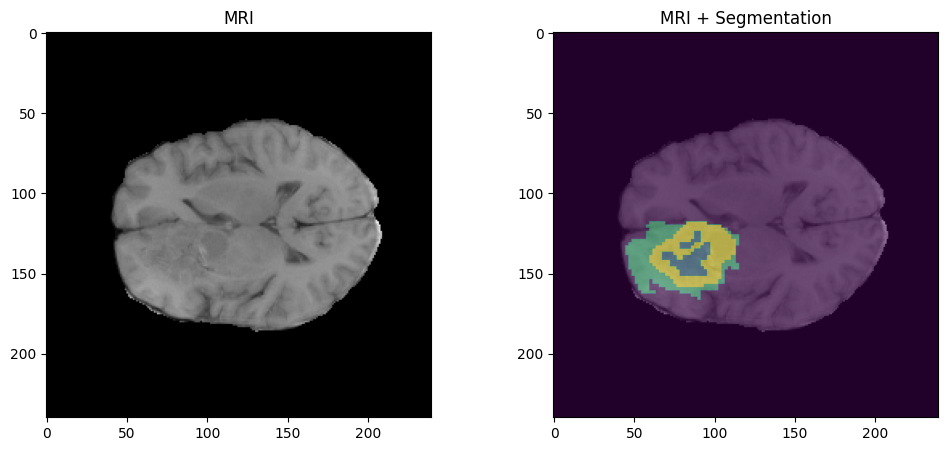

In [26]:
import matplotlib.pyplot as plt

img_data = img.get_fdata()
seg_data = seg.get_fdata()

slice_id = img_data.shape[2] // 2

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.imshow(img_data[:, :, slice_id], cmap="gray")
plt.title("MRI")

plt.subplot(1,2,2)
plt.imshow(img_data[:, :, slice_id], cmap="gray")
plt.imshow(seg_data[:, :, slice_id], alpha=0.5)
plt.title("MRI + Segmentation")

plt.show()


In [27]:
voxel_volume = abs(np.linalg.det(img.affine[:3, :3]))

for label, name in [(1,"ET"), (2,"TC"), (3,"WT")]:
    voxels = np.sum(seg_data == label)
    volume = voxels * voxel_volume
    print(f"{name}: {volume:.2f} mm³")


ET: 10602.00 mm³
TC: 27765.00 mm³
WT: 41175.00 mm³


In [28]:
from radiomics import featureextractor

extractor = featureextractor.RadiomicsFeatureExtractor()
extractor.enableAllFeatures()

result = extractor.execute(
    "E:/Radiomics/example/BraTS2021_00000_t1.nii.gz",
    "E:/Radiomics/example_masks/BraTS2021_00000_pred_seg.nii.gz",
    label=1   # ET
)

print("Extracted features:", len(result))


parameter force2D must be set to True to enable shape2D extraction
GLCM is symmetrical, therefore Sum Average = 2 * Joint Average, only 1 needs to be calculated


Extracted features: 129


Loading MRI volumes...
Loading masks...
Fusing MRI...
Computing Dice scores...
WT Dice: 0.8385
TC Dice: 0.4211
ET Dice: 0.0000
Extracting brain mesh...
Extracting tumor meshes...


Widget(value='<iframe src="http://localhost:58651/index.html?ui=P_0x1f78aaf12d0_0&reconnect=auto" class="pyvis…

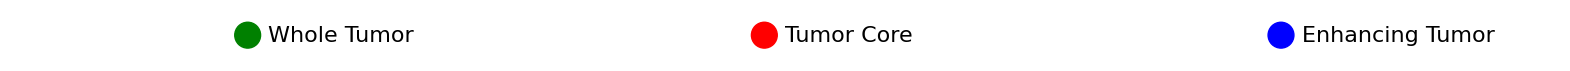

In [1]:
import os
import numpy as np
import nibabel as nib
from skimage import measure
from scipy.ndimage import gaussian_filter
import trimesh
import pyvista as pv

# -----------------------------
# CONFIG
# -----------------------------
DATA_DIR = "E:/Radiomics/example"
PRED_DIR = "E:/Radiomics/example_masks"
PATIENT_ID = "BraTS2021_00000"
OUTPUT_DIR = "E:/Radiomics/example_masks"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# -----------------------------
# UTILS
# -----------------------------
def load_nifti(path):
    nii = nib.load(path)
    return nii.get_fdata()

def normalize(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)

def dice_score(pred, gt, label):
    pred_l = (pred == label)
    gt_l = (gt == label)
    inter = np.sum(pred_l & gt_l)
    union = np.sum(pred_l) + np.sum(gt_l)
    if union == 0:
        return 1.0
    return 2.0 * inter / union

# -----------------------------
# LOAD DATA
# -----------------------------
print("Loading MRI volumes...")
flair = load_nifti(f"{DATA_DIR}/{PATIENT_ID}_flair.nii.gz")
t1 = load_nifti(f"{DATA_DIR}/{PATIENT_ID}_t1.nii.gz")
t1ce = load_nifti(f"{DATA_DIR}/{PATIENT_ID}_t1ce.nii.gz")
t2 = load_nifti(f"{DATA_DIR}/{PATIENT_ID}_t2.nii.gz")

print("Loading masks...")
gt = load_nifti(f"{DATA_DIR}/{PATIENT_ID}_seg.nii.gz")
pred = load_nifti(f"{PRED_DIR}/{PATIENT_ID}_pred_seg.nii.gz")

# -----------------------------
# FUSE MRI
# -----------------------------
print("Fusing MRI...")
flair = normalize(flair)
t1 = normalize(t1)
t1ce = normalize(t1ce)
t2 = normalize(t2)

fused = (0.3 * flair + 0.2 * t1 + 0.3 * t1ce + 0.2 * t2)
fused = gaussian_filter(fused, sigma=1)

# -----------------------------
# DICE
# -----------------------------
print("Computing Dice scores...")
regions = {"WT": 1, "TC": 2, "ET": 3}
dice_scores = {}

for name, lab in regions.items():
    d = dice_score(pred, gt, lab)
    dice_scores[name] = d
    print(f"{name} Dice: {d:.4f}")

best_region = max(dice_scores, key=dice_scores.get)

# -----------------------------
# MESH EXTRACTION
# -----------------------------
print("Extracting brain mesh...")
brain_mask = fused > np.percentile(fused, 40)
v, f, _, _ = measure.marching_cubes(brain_mask, 0.5)
brain_mesh = trimesh.Trimesh(v, f, process=False)

print("Extracting tumor meshes...")
colors = {
    "WT": [255, 0, 0, 255],
    "TC": [0, 255, 0, 255],
    "ET": [0, 0, 255, 255]
}
tumor_meshes = {}
for name, lab in regions.items():
    mask = (pred == lab)
    if np.sum(mask) < 20: continue
    v_t, f_t, _, _ = measure.marching_cubes(mask, 0.5)
    m = trimesh.Trimesh(v_t, f_t, process=False)
    m.visual.face_colors = colors[name]
    tumor_meshes[name] = m

import pyvista as pv

# -----------------------------
# INTERACTIVE 3D VISUALIZATION
# -----------------------------

def show_interactive_brain(brain_mesh, tumor_meshes, dice_scores):
    # This backend enables interactive 3D within VS Code cells
    pv.set_jupyter_backend('client') 

    plotter = pv.Plotter(window_size=[800, 600])
    plotter.set_background("black")

    # 1. Add Brain (Transparent)
    brain_pv = pv.wrap(brain_mesh)
    plotter.add_mesh(brain_pv, color="silver", opacity=0.1, label="Brain")

    # 2. Add Tumor Regions
    pv_colors = {"WT": "red", "TC": "green", "ET": "blue"}
    for name, mesh in tumor_meshes.items():
        tumor_pv = pv.wrap(mesh)
        plotter.add_mesh(
            tumor_pv, 
            color=pv_colors[name], 
            label=f"{name} (Dice: {dice_scores[name]:.3f})"
        )

    # 3. Add the FIXED Legend
    # Legend is pinned to the camera view and won't rotate with the brain
    plotter.add_legend(
        bcolor=(0.1, 0.1, 0.1), 
        size=(0.2, 0.2)
    )

    # 4. Add Label
    plotter.add_text(f"Patient ID: {PATIENT_ID}", position='upper_left', font_size=10)

    # Display the rotatable element
    plotter.show()

# Execute
show_interactive_brain(brain_mesh, tumor_meshes, dice_scores)

import matplotlib.pyplot as plt
import matplotlib.patches as patches

def draw_status_bar():
    # 1. Configuration
    items = [('green', 'Whole Tumor'), ('red', 'Tumor Core'), ('blue', 'Enhancing Tumor')]
    fig_width = 20
    fig_height = 0.8
    
    # 2. Create Figure and Axis
    # We use a specific figsize and set the background to white
    fig, ax = plt.subplots(figsize=(fig_width, fig_height))
    
    # Define coordinate system: x from 0 to 30, y from 0 to 1
    ax.set_xlim(0, 30)
    ax.set_ylim(0, 1)
    
    # 4. Calculate Equal Spacing
    # We divide the width (10) into 3 equal parts.
    # The centers of these parts are at 1/6, 1/2, and 5/6 of the total width.
    positions = [5.0, 15.0, 25.0]
    circle_radius = 0.25 
    
    for i, (color, label) in enumerate(items):
        center_x = positions[i]
        
        # Draw Circle (slightly left of the center to balance the group)
        circle_x = center_x - 0.4
        circle = patches.Circle((circle_x, 0.5), circle_radius, color=color)
        ax.add_patch(circle)
        
        # Draw Text (directly to the right of the circle)
        ax.text(circle_x + 0.4, 0.5, label, ha='left', va='center', 
                fontsize=16, fontweight='light', color='black')

    # 5. Final Formatting
    ax.set_aspect('equal', adjustable='box') # Keeps circles round
    ax.axis('off') # Hides axis lines and ticks
    plt.show()

draw_status_bar()